In [1]:
# Cell 1 - Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, os, warnings
warnings.filterwarnings('ignore')
print("Libraries loaded.")

Libraries loaded.


In [2]:
# Cell 2 - Load All Metric Results
with open('../outputs/reports/lstm_metrics.json')   as f: lstm_m   = json.load(f)
with open('../outputs/reports/gru_metrics.json')    as f: gru_m    = json.load(f)
with open('../outputs/reports/hybrid_metrics.json') as f: hybrid_m = json.load(f)
print("LSTM   :", lstm_m)
print("GRU    :", gru_m)
print("Hybrid :", hybrid_m)

LSTM   : {'RMSE': 6.462773164919311, 'MAE': 5.126912593841553, 'R2': -0.26602840423583984, 'MAPE': 36.17549514770508}
GRU    : {'RMSE': 7.301623741266952, 'MAE': 5.884156703948975, 'R2': -0.6160117387771606, 'MAPE': 38.79136276245117}
Hybrid : {'RMSE': 6.497089908305974, 'MAE': 5.165072441101074, 'R2': -0.2795090675354004, 'MAPE': 36.611209869384766}


In [3]:
# Cell 3 - Comparison Table
results_df = pd.DataFrame({
    'Model'   : ['LSTM', 'GRU', 'Hybrid CNN-LSTM-GRU'],
    'RMSE'    : [lstm_m['RMSE'],  gru_m['RMSE'],  hybrid_m['RMSE']],
    'MAE'     : [lstm_m['MAE'],   gru_m['MAE'],   hybrid_m['MAE']],
    'R2'      : [lstm_m['R2'],    gru_m['R2'],    hybrid_m['R2']],
    'MAPE_%'  : [lstm_m['MAPE'],  gru_m['MAPE'],  hybrid_m['MAPE']],
}).set_index('Model')
print("\n" + "="*55)
print("         MODEL COMPARISON RESULTS")
print("="*55)
print(results_df.to_string())
print("="*55)
best_model = results_df['RMSE'].idxmin()
print(f"\n Best Model (lowest RMSE): {best_model}")


         MODEL COMPARISON RESULTS
                         RMSE       MAE        R2     MAPE_%
Model                                                       
LSTM                 6.462773  5.126913 -0.266028  36.175495
GRU                  7.301624  5.884157 -0.616012  38.791363
Hybrid CNN-LSTM-GRU  6.497090  5.165072 -0.279509  36.611210

 Best Model (lowest RMSE): LSTM


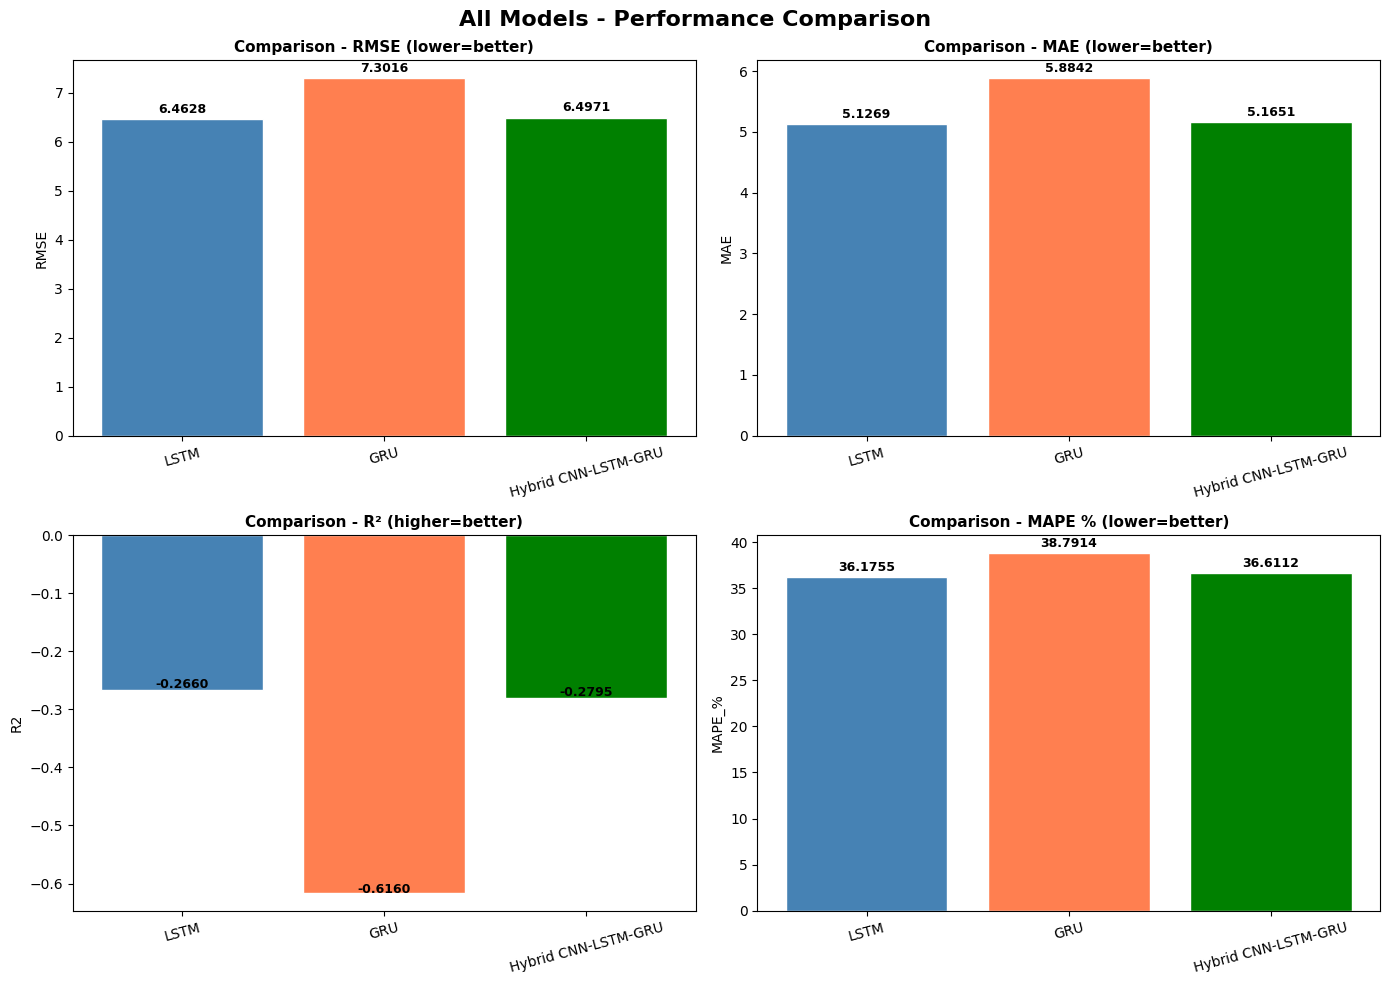

In [4]:
# Cell 4 - Bar Chart Comparison (2x2)
os.makedirs('../outputs/plots', exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ['RMSE', 'MAE', 'R2', 'MAPE_%']
labels  = ['RMSE (lower=better)', 'MAE (lower=better)', 'R² (higher=better)', 'MAPE % (lower=better)']
colors  = ['steelblue', 'coral', 'green']
for idx, (metric, label) in enumerate(zip(metrics, labels)):
    ax = axes[idx // 2][idx % 2]
    bars = ax.bar(results_df.index, results_df[metric], color=colors, edgecolor='white')
    ax.set_title(f'Comparison - {label}', fontweight='bold', fontsize=11)
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=15)
    for bar, val in zip(bars, results_df[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height() * 1.01,
                f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.suptitle('All Models - Performance Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/07_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

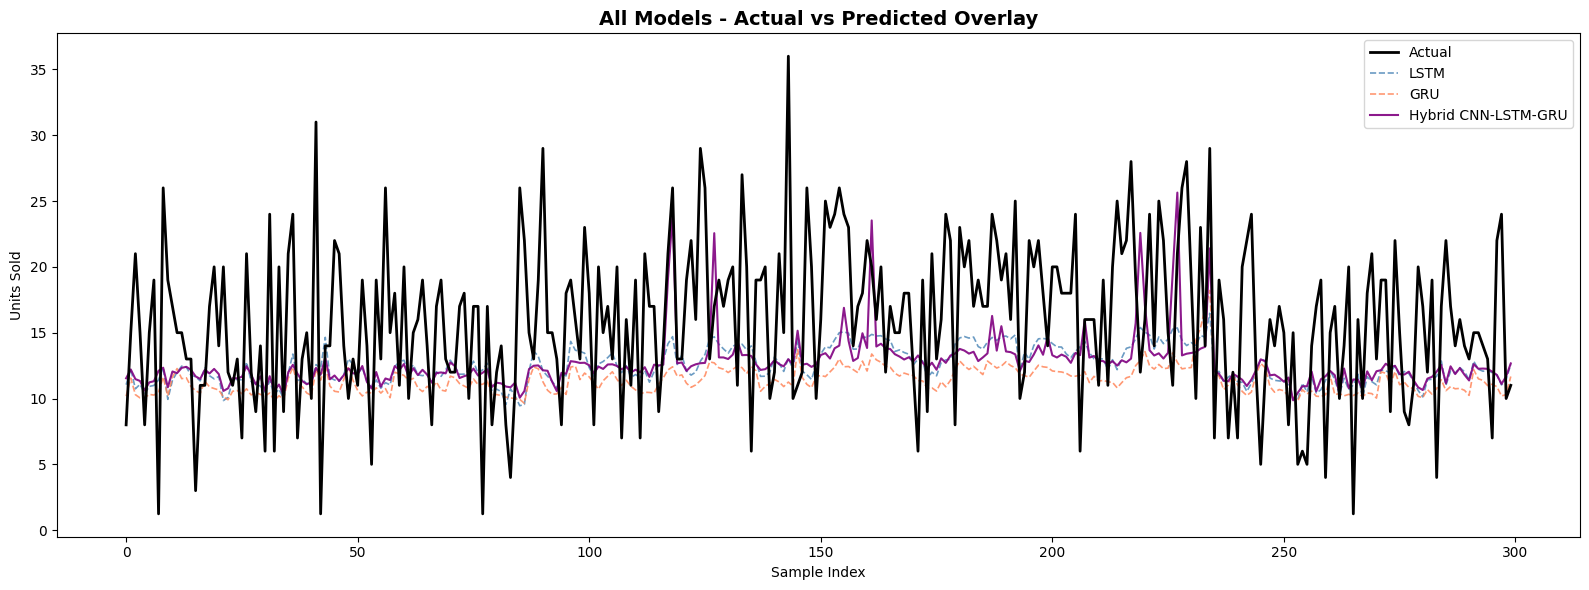

In [5]:
# Cell 5 - Overlay All Predictions
y_true      = np.load('../data/processed/y_true_test.npy')
lstm_pred   = np.load('../data/processed/lstm_predictions.npy')
gru_pred    = np.load('../data/processed/gru_predictions.npy')
hybrid_pred = np.load('../data/processed/hybrid_predictions.npy')

n_plot = min(300, len(y_true))
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(y_true[:n_plot],      label='Actual',              color='black',     linewidth=2,   zorder=4)
ax.plot(lstm_pred[:n_plot],   label='LSTM',                color='steelblue', linewidth=1.2, linestyle='--', alpha=0.8)
ax.plot(gru_pred[:n_plot],    label='GRU',                 color='coral',     linewidth=1.2, linestyle='--', alpha=0.8)
ax.plot(hybrid_pred[:n_plot], label='Hybrid CNN-LSTM-GRU', color='purple',    linewidth=1.5, alpha=0.9)
ax.set_title('All Models - Actual vs Predicted Overlay', fontsize=14, fontweight='bold')
ax.set_xlabel('Sample Index'); ax.set_ylabel('Units Sold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('../outputs/plots/07_all_models_overlay.png', dpi=150, bbox_inches='tight')
plt.show()

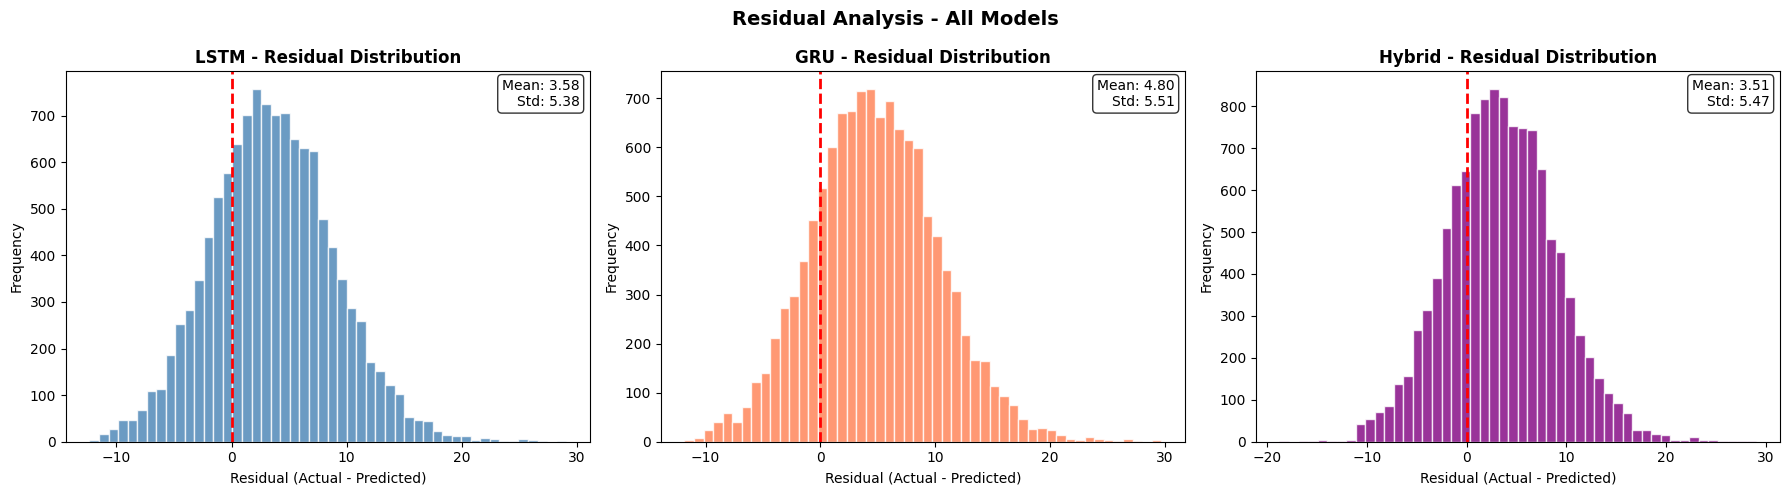

In [6]:
# Cell 6 - Residual Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_preds = [('LSTM', lstm_pred, 'steelblue'), ('GRU', gru_pred, 'coral'), ('Hybrid', hybrid_pred, 'purple')]
for idx, (name, preds, color) in enumerate(model_preds):
    residuals = y_true - preds
    axes[idx].hist(residuals, bins=50, edgecolor='white', color=color, alpha=0.8)
    axes[idx].axvline(0, color='red', linestyle='--', linewidth=2)
    axes[idx].set_title(f'{name} - Residual Distribution', fontweight='bold')
    axes[idx].set_xlabel('Residual (Actual - Predicted)')
    axes[idx].set_ylabel('Frequency')
    axes[idx].text(0.98, 0.98, f'Mean: {residuals.mean():.2f}\nStd: {residuals.std():.2f}',
                   transform=axes[idx].transAxes, ha='right', va='top',
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.suptitle('Residual Analysis - All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/07_residual_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# Cell 7 - Normalized Radar Score Table
max_rmse = results_df['RMSE'].max()
max_mae  = results_df['MAE'].max()
max_mape = results_df['MAPE_%'].max()

radar_df = pd.DataFrame({
    'RMSE_score' : 1 - results_df['RMSE']   / max_rmse,
    'MAE_score'  : 1 - results_df['MAE']    / max_mae,
    'R2_score'   : results_df['R2'],
    'MAPE_score' : 1 - results_df['MAPE_%'] / max_mape
})
print("Normalized Scores (higher = better for all):")
print(radar_df.to_string())
print("\nOverall rank (sum of scores):")
print(radar_df.sum(axis=1).sort_values(ascending=False).to_string())

Normalized Scores (higher = better for all):
                     RMSE_score  MAE_score  R2_score  MAPE_score
Model                                                           
LSTM                   0.114885   0.128692 -0.266028    0.067434
GRU                    0.000000   0.000000 -0.616012    0.000000
Hybrid CNN-LSTM-GRU    0.110186   0.122207 -0.279509    0.056202

Overall rank (sum of scores):
Model
LSTM                   0.044983
Hybrid CNN-LSTM-GRU    0.009085
GRU                   -0.616012


In [8]:
# Cell 8 - Save Comparison Report
os.makedirs('../outputs/reports', exist_ok=True)
results_df.to_csv('../outputs/reports/model_comparison.csv')
radar_df.to_csv('../outputs/reports/normalized_scores.csv')
print("\n✅ Model Evaluation Complete!")
print(f"Best Model by RMSE : {best_model}")
print("Reports saved to   : outputs/reports/")


✅ Model Evaluation Complete!
Best Model by RMSE : LSTM
Reports saved to   : outputs/reports/
